# Data visualization and preprocessing

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import sys
sys.path.append("..")

PROJECT_ROOT = Path.cwd().resolve().parent   
sys.path.insert(0, str(PROJECT_ROOT)) 


from src.datasets.build_dataset import build_cohort_b_dataset
from src.datasets.cleaning import filter_physiological_outliers, preprocess_glucose, extract_eligible_blocks
from src.visualization.eda_plots import plot_participant_boxplots, plot_participant_mean_cv, inter_individual_spread, plot_glucose_evol_day, plot_daily_mean, plot_hour_day_heatmap, plot_input_vs_target_mean
from src.datasets.data_splitting import split_and_save_cohort
from src.datasets.features import split_input_target, compute_cgm_features, compute_targets_features, build_xy
from src.datasets.glucose_audit import load_cohort_b, check_timezone, check_outliers, check_units, check_gaps, FIG

In [3]:
%matplotlib inline

## Data loading

CGM recordings of participants from the same cohort, with times and dates of recording

In [4]:
build_cohort_b_dataset()
DATA_DIR = Path("../../data/processed")
data = pd.read_csv(DATA_DIR / "cohort_b_glucose_data.csv")

Glucose IDs: 1119 | Metadata IDs: 1013 | Matched: 1009
Unmatched glucose IDs: 110 | Unmatched metadata IDs: 4
Cohort B participants: 864 | Rows: 1149316


## Glucose audit - data quality

Before proceeding with data preprocessing, we perform a quality audit of the raw Cohort B glucose data.

The audit checks four aspects:
- **Timezone:** determine whether timestamps are in UTC or already in Swiss time.
- **Outliers:** identify suspicious glucose values without removing them.
- **Units:** check whether glucose measurements are expressed in mmol/L.
- **Gaps:** analyze missing periods between consecutive glucose readings.

The audit functions are imported from `src/datasets/glucose_audit.py` to avoid duplicating code.

In [5]:
df = load_cohort_b()

FIG.mkdir(parents=True, exist_ok=True)

check_timezone(df)
check_outliers(df)
check_units(df)
check_gaps(df)


== 1. Timezone: hour of the night trough ==
  raw hours in the file       : 3 h
  converted to Swiss time     : 5 h
  winter (raw hours)          : 4 h
  summer (raw hours)          : 2 h

== 2. Outliers ==
  min / max value                 : 1.43 / 27.80
  missing or <= 0                 : 0
  below 2.0                       : 3
  above 27.8                     : 0
  above 25.0                     : 194
  flat runs of 12+ identical readings : 211

== 3. Units ==
  participant means, min / max          : 3.62 / 11.62
  participants with a mean above 30     : 0 (likely mg/dL)

== 4. Gaps (> 30 min) ==
  number of gaps: 4541
ts
30 min-1 h    1441
1-2 h         1495
2-6 h         1225
6-24 h         238
over 24 h      142
  participants with a gap over 24 h : 99
  longest gap, median / max         : 2.3 h / 18888.9 h


The results of these checks will help us make informed decisions during preprocessing.
No data is removed or modified during this audit. The identified issues will be considered when defining the cleaning and preprocessing steps.

## Glucose distribution visualization

In [6]:
stats = inter_individual_spread(data)
print (stats)

min                 3.4150
Q1                  4.9000
median              5.2250
Q3                  5.5925
max                10.1000
IQR                 0.6925
n_participants    864.0000
Name: val, dtype: float64


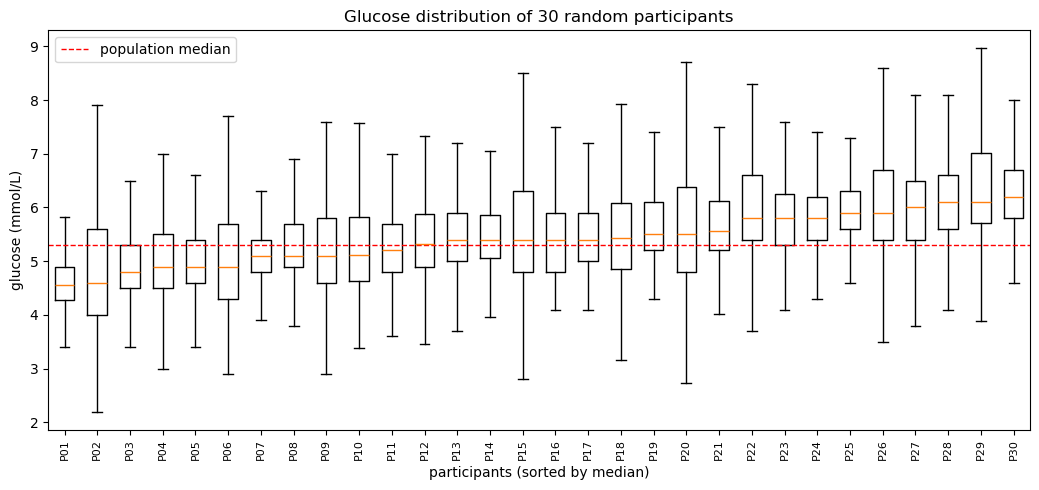

In [7]:
plot_participant_boxplots(data)

,user_id,n_readings,mean,std,cv
participant_rank,,,,,
1,1784,790,3.615823,0.637438,17.629129
2,89,1334,3.643028,0.889158,24.407099
3,1674,797,3.848306,0.830504,21.581020
4,61,1338,3.981472,0.694077,17.432660
5,24,1434,4.031444,0.816559,20.254750
...,...,...,...,...,...
860,2091,1266,7.247709,0.886508,12.231557
861,2029,1271,7.816129,2.200311,28.150907
862,109,1234,7.844571,1.665520,21.231500


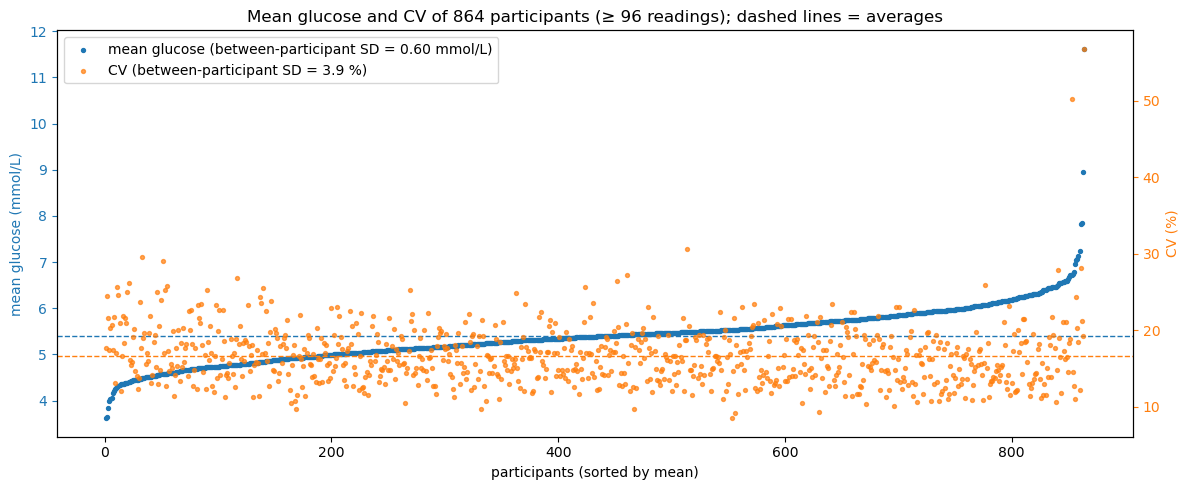

In [8]:
plot_participant_mean_cv(data)

## Preprocessing

remove outliers and missing values, deal with different timestamps, and select eligible participants

In [9]:
data_good_time = preprocess_glucose("cohort_b_glucose_data.csv")
data_clean = filter_physiological_outliers(data_good_time)
data_preprocess, _, _ = extract_eligible_blocks(data_clean)

Preprocessed 1147629 bins across 864 participants -> /Users/laetitiaespinosa/Documents/EPFL/Cours/MA1/ML/ML_project2/data/processed/glucose_cleaned.csv
[1/3] Outlier filter [2.0, 27.8 mmol/L]: removed 3 rows (1147626 remaining)
Eligible cohort (12d consecutive >= 75%): 673 participants -> /Users/laetitiaespinosa/Documents/EPFL/Cours/MA1/ML/ML_project2/data/processed/glucose_eligible_12d.csv


### Glucose evolution visualization

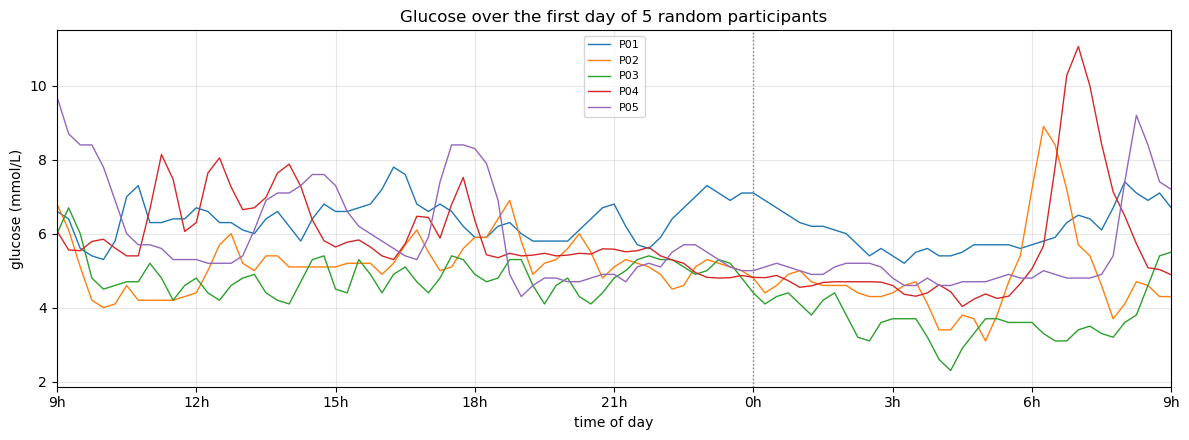

In [10]:
plot_glucose_evol_day(data_preprocess)

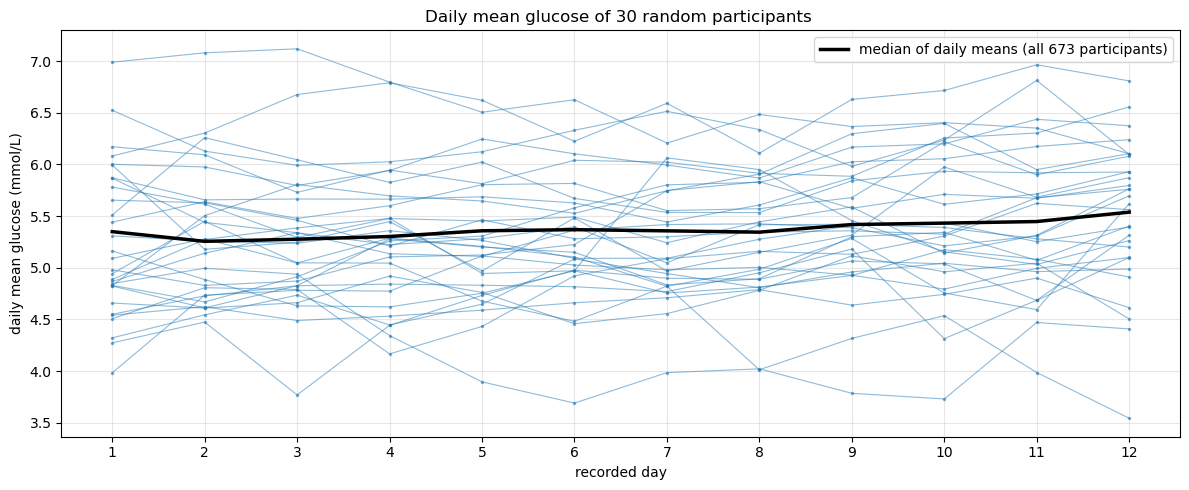

In [11]:
plot_daily_mean(data_preprocess)

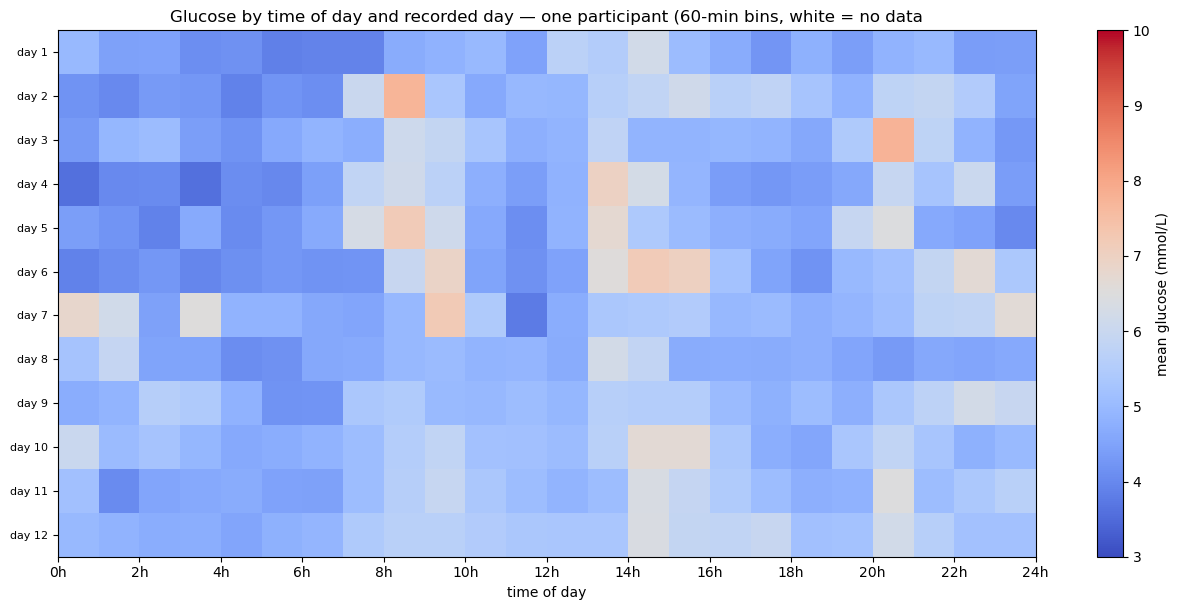

In [12]:
plot_hour_day_heatmap(data_preprocess)

## Split train and test data

In [13]:
train_data, val_data, test_data = split_and_save_cohort(data_preprocess)

Saved train_12d.csv   : 471 participants (532010 bins)
Saved val_12d.csv     : 100 participants (113163 bins)
Saved test_12d.csv    : 102 participants (115286 bins)


## Compute glucose data features for different durations

K = 1 day

In [14]:
input_df_1d, target_df = split_input_target(train_data, k_days=1)
features_1d = compute_cgm_features(input_df_1d, night_hours=(0, 6), day_hours=(8, 20))
target = compute_targets_features (target_df)


K = 3 days

In [15]:
input_df_3d, target_df = split_input_target(train_data, k_days=3)
features_3d = compute_cgm_features(input_df_3d, night_hours=(0, 6), day_hours=(8, 20))

K = 5 days

In [16]:
input_df_5d, target_df = split_input_target(train_data, k_days=5)
features_5d = compute_cgm_features(input_df_5d, night_hours=(0, 6), day_hours=(8, 20))

K = 7 days

In [17]:
input_df_7d, target_df = split_input_target(train_data, k_days=7)
features_7d = compute_cgm_features(input_df_7d, night_hours=(0, 6), day_hours=(8, 20))

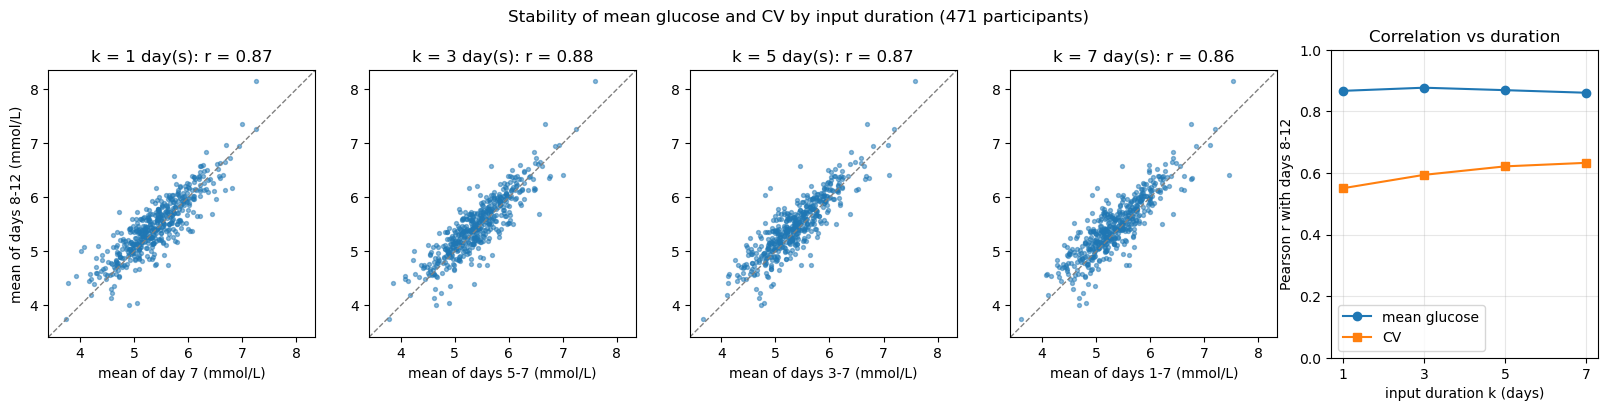

In [18]:
plot_input_vs_target_mean(train_data)